# Numerical Solution to Schrodingers Equation Using SBP Operator

## Motivation

TThe solution to the Schrodinger equation $\Psi$ is a complex function in terms of spatial coordinates and time which has some useful properties. Two such properties will be shown as an example. When the square of the norm of the wavefunction $\Psi$ is taken, (given by $||\Psi||^2=\Psi^* \Psi$) the resulting function is a probability density function that described the probability of a particle being measured in some domain at some time. When the Fourier transform is taken then again the mod-squared it yields (up to a factor of $\hbar$, namely plancks reduced constant) a probaility density function of a particle lying within a some domain of momentum at some time. 

The Schrodinger equation in one spatial dimension is 
$$
-\frac{\hbar^2}{2m}\frac{\partial^2 \Psi}{\partial x^2} + V\Psi = i\hbar\frac{\partial \Psi}{\partial t}
$$

Where $m$ is the mass and $V$ is the potential, which is a Hermitian operator. To first solve the Schrodinger equation a potential energy must be defined in terms of spatial coordinates and time. Two such examples of systems with potential energy are
1. Those with 0 potential on a finite domain and infinity elsewhere, commonly known as the infinite square well
2. The harmonic oscillator which a system that has a force negatively proportional to the distance from some defined origin.

This particular problem has been chosen in order to extend the second order SBP operator in one-dimension to the case where the solution has an extra linear term and where the solution may be complex . This involves rethinking how to prove stability as well as redefining the $L^2$ norm, the scalar product and the discrete scalar product and using them as such. 

The wavefunction in quantum mechanics is continuous, so if the wavefunction is non-zero only on a finite interval then the boundary condition for both sides must be 0, i.e. $\Psi(0,t)=0=\Psi(L,t)$

## Analytic Stability

To create a numerical solution of this equation, the wavefunction must be defined on some finite interval which will be taken to be $[0,L]$. When creating numerical solutions the solutions that are obtained sometimes grow arbitrarily which render them unusable. So we wish to show that the solution to the Schrodinger equation will not grow arbitrarily. So it needs to be shown that the norm of the solution $||\Psi||^2$ is bounded. To show that it is bounded for all time it needs to be shown that the norm of the solution is non-increasing. This will give the required result as the initial condition will have a finite norm and so will not grow. To show this, first take the Schrodinger equation as stated above and multiply by the complex conjugate and integrate over the the whole real line (which is equivalent to integrating over the finite interval since the solution is 0 everywhere outside). This will give a term which is the norm of $\Psi$. Once isolating the time derivative term this gives
\begin{align*}
i\frac{\hbar}{2m}\int_{0}^{L} \frac{\partial^2 \Psi}{\partial x^2}\Psi^* - \frac{i}{\hbar}V||\Psi||^2 & =\int_{0}^{L}\frac{\partial \Psi}{\partial t}\Psi^*
\end{align*}	
Integration by parts on the first integral gives
$$
i\frac{\hbar}{2m}\left( \Psi^* \frac{\partial \Psi}{\partial x} \Big|_0^L - \int_{0}^{L} \frac{\partial \Psi}{\partial x}\frac{\partial \Psi^*}{\partial x}  \right) - \frac{i}{\hbar}V||\Psi||^2  = \int_{0}^{L}\frac{\partial \Psi}{\partial t}\Psi^*
$$
If a new equation, which is exactly the conjugate of both sides, is added to this equation it yields
$$
\frac{i\hbar}{2m}\left( \Psi^*\frac{\partial \Psi}{\partial x}-\Psi \frac{\partial \Psi^*}{\partial x} \right)\Big|_0^L = \frac{d}{dt}\left( ||\Psi||^2 \right)
$$
However at the boundaries $\Psi=0$, which will give $\frac{d}{dt}||\Psi||^2=0$ 

## Discretising the Scalar Product

Now to create a numerical solution for the PDE firstly the interval of the solution must be discretised into $N+1$ grid points. These points will be uniform across the interval with distance $\Delta x=\frac{1}{N}$ such that the $j^{th}$ grid point $x_j$ is at $x=j\Delta x$. This solution will be an array of $N+1$ points $\textbf{u}=[u_0\; u_1 \dots u_{N+1}]$ where $u_i=u(x_i)$. 

Now the work here is all being done with complex functions, so the scalar product for real functions has to be redefined on a finite interval $[0,L]$ as
$$
\langle u,v \rangle = \int_{-\infty}^{\infty} u^*(x) v(x) dx = \int_0^L u^*(x)v(x)dx
$$
To discretise this, an approximation of the integral must be made. This approximation will be using $N$ rectangles across the interval with height $u_j^*v_j$ and width $h_j$. So the discrete approximation of the scalar product is 
$$
\langle u,v \rangle _H = \sum_{j=1}^n u_j^* v_j h_j = \textbf{u}^{\dagger} \textbf{H} \textbf{v}
$$
Where $\textbf{u}^{\dagger}$ is the conjugate transpose of the array $\textbf{u}$ and $\textbf{H}$ is a matrix with diagonal entries $h_j$. Seeing these are widths of a rectangle $h_j$ is real and $h_j>0$ for all $j$. This matrix is hermitian.

## SBP Operators

### First Derivative 

When the scalar product $\langle u, \frac{\partial v}{\partial x} \rangle$ is taken, this can be separated using integration by parts to give
$$
\langle u, \frac{\partial v}{\partial x} \rangle + \langle \frac{\partial u}{\partial x}, v \rangle = u^*v\big|_0^L
$$
A discrete derivative operator $\textbf{D}_{x}$ is an SBP operator (summation by parts) if it mimics this integration by parts behaviour on the discrete level. This would look like
$$
\textbf{u}^{\dagger}\textbf{HD}_{x}\textbf{v}+\textbf{u}^{\dagger}\textbf{D}_x^T\textbf{H}\textbf{v}=\textbf{u}^{\dagger}\textbf{Bv}
$$
Where $\textbf{B}$ is the boundary matrix given by 
$$
\textbf{B} =
\begin{pmatrix}
-1 & 0 &  & & \\
0 & 0 & & &  \\
 &  & \ddots &  &  \\
 & & & 0 & 0 \\
 &  &  & 0 & 1
\end{pmatrix}
= \textbf{e}_N \textbf{e}_N^T - \textbf{e}_0 \textbf{e}_0^T
$$

With $\textbf{e}_i$ being the $i^{th}$ basis vector, i.e. with a 1 at the $i^{th}$ entry and 0 elsewhere. Now let $\textbf{HD}_x=\textbf{Q}$. So rearranging for $\textbf{D}_x$ yields $\textbf{D}_x=\textbf{H}^{-1}\textbf{Q}$ where (from the above equation) $\textbf{Q}+\textbf{Q}^T=\textbf{B}$. 
### Second Derivative

When the scalar product $\langle u, \frac{\partial ^2 v}{\partial x^2} \rangle$ is taken, this can be separated using integration by parts to 
$$
\langle u, \frac{\partial ^2 v}{\partial x^2} \rangle= u^* \frac{\partial v}{\partial x}\Big|_0^L - \langle \frac{\partial u}{\partial x}, \frac{\partial v}{\partial x} \rangle
$$
A discrete double derivative operator $\textbf{D}_{xx}$ is SBP (summation by parts) if it mimics this integration by parts behaviour on the discrete level. This would look like 
$$
\langle \textbf{u}, \textbf{D}_{xx} \textbf{v} \rangle  _H = \textbf{u}^{\dagger} \textbf{H} \textbf{D}_{xx} \textbf{v} = u_N^* (\textbf{Sv})_N - u_0^* (\textbf{Sv})_0 - \textbf{u}^{\dagger} \textbf{M} \textbf{v} 
$$
Where $\textbf{M}$ is a matrix that is symmetric and positive semi-definite and $\textbf{S}$ is a matrix that approximates the derivative on the boundaries.

The operator which is $\textbf{D}_{xx}=\textbf{H}^{-1}(-\textbf{M}+\textbf{B}\textbf{S})$ will accomplish this.

### Compatible Operators

The two SBP operators $\textbf{D}_x$ and $\textbf{D}_{xx}$ are called $\textit{fully compatible}$ if 
$$
\textbf{M}=\textbf{D}_x\textbf{H}\textbf{D}_x+\textbf{R}_x\\
\textbf{S}=\textbf{D}_x
$$
Where $R_x$ is positive semi-definite.


All the matrices are real and so their conjugate does not change the matrices. Since the matrices are also symmetric they are thus hermitian.

## Semi-Discretisation

To construct a numerical method now the IBVP must be discretised. The domain has been discretised so now the PDE must be discretised. The PDE hence becomes 
$$
\frac{d\textbf{u}}{dt}=-\frac{i\hbar}{2m}\textbf{D}_{xx}\textbf{u}+\frac{i}{\hbar}\textbf{Vu}
$$

Where $\textbf{V}$ is a diagonal hermitian matrix that has entries $\textbf{V}_{(i,i)}=V(x_i, t)$

So to now complete the semi-discretisation now the boundary conditions must be discretised. For boundary terms $\Psi(0,t)=0=\Psi(L,t)$ the boundary matrix $\textbf{B}$ applied to the solution will look like 
$$
\textbf{Bu}=
\begin{pmatrix}
-u_0(t)\\
0\\
\vdots\\
0\\
u_n(t)
\end{pmatrix}
$$

Note that although the boundary conditions are 0 that the numerical solution may have a slight error from this hence the non-zero entries.

When using the SBP operator the boundary conditions are implemented weakly using SAT terms (simultaneous approximation terms). For Dirichlet boundary conditions in a second order PDE problem there is two SAT terms. The discrete PDE with SAT terms becomes
$$
\frac{d\textbf{u}}{dt}=-\frac{i\hbar}{2m}\textbf{D}_{xx}\textbf{u}+\frac{i}{\hbar}V\textbf{u} + \frac{i\hbar}{2m}\tau_1 \textbf{H}^{-1}\textbf{D}_x^T \textbf{Bu}-\frac{i\hbar}{2m}\tau_0\textbf{H}^{-1}\textbf{B}^T \textbf{H}^{-1}\textbf{Bu}
$$

Where $\tau_0$, $\tau_1$ are penalty parameters which will be determined later to give stability

## Discrete Stability
Now to show that the numerical solution is stable and will not blow up to arbitrary values the same result from analytic stability needs to be shown but using the discrete norm. That is, it must be shown that time derivative the $L^2$ norm of the solution, i.e. $\frac{d}{dt}(\textbf{u}^{\dagger}\textbf{H}\textbf{u})\leq 0$. To show this first start with the discrete equation with SAT terms and multiply on the left by $\textbf{H}$

$$
\textbf{H}\frac{d\textbf{u}}{dt}=\frac{i\hbar}{2m}\textbf{HD}_{xx}\textbf{u}-\frac{i}{\hbar}\textbf{Vu}+\frac{i\hbar}{2m}\tau_1 \textbf{D}_x^T \textbf{Bu}-\frac{i\hbar}{2m}\tau_0\textbf{B}^T \textbf{H}^{-1}\textbf{Bu}
$$

Now the SBP property for $\textbf{D}_{xx}$ can be used to give 

$$
\textbf{H}\frac{d\textbf{u}}{dt}=\frac{i\hbar}{2m}(-\textbf{M}+\textbf{BS})\textbf{u}+\frac{i\hbar}{2m}\tau_1 \textbf{D}_x^T \textbf{Bu}-\frac{i\hbar}{2m}\tau_0\textbf{B}^T \textbf{H}^{-1}\textbf{Bu}-\frac{i}{\hbar}\textbf{Vu}
$$

Now the compatibility properties can be used on $\textbf{M}$ and $\textbf{S}$ to give

$$
\textbf{H}\frac{d\textbf{u}}{dt}=\frac{i\hbar}{2m}(-\textbf{D}_x^T\textbf{HD}_x-\textbf{R}_x+\textbf{BD}_x)\textbf{u}+\frac{i\hbar}{2m}v\tau_1 \textbf{D}_x^T \textbf{Bu}-\frac{i\hbar}{2m}\tau_0\textbf{B}^T \textbf{H}^{-1}\textbf{Bu}-\frac{i}{\hbar}\textbf{Vu}
$$

Now some values will be assigned to the penalty terms. Notice the $\tau_1$ term is the transpose of the term $\textbf{BD}_x$, so to create symmetry $\tau_1=1$. Let $\tau_0=1+\alpha_0$ where $\alpha_0\leq0$ to ensure that $\tau_0$ is 1 or greater. This yields

$$
\textbf{H}\frac{d\textbf{u}}{dt}=\frac{i\hbar}{2m}(-\textbf{D}_x^T\textbf{HD}_x+\textbf{BD}_x+\textbf{D}_x^T\textbf{B}+\textbf{B}^T \textbf{H}^{-1}\textbf{B})\textbf{u}-\textbf{R}_x\textbf{u}-\frac{i\hbar}{2m}\alpha_0\textbf{B}^T \textbf{H}^{-1}\textbf{Bu}-\frac{i}{\hbar}\textbf{Vu}
$$

Now the terms in the brackets after simplification (proof omitted) equal $-(\textbf{D}_x-\textbf{H}^{-1}\textbf{B})^T\textbf{H}(\textbf{D}_x-\textbf{H}^{-1}\textbf{B})$ which be defined to equal $\overline{\textbf{M}}$. Now consider $\textbf{u}^{\dagger}\overline{\textbf{M}}\textbf{u}$, this is the norm of $(\textbf{D}_x-\textbf{H}^{-1}\textbf{B})\textbf{u}$, which is by definition positive, so $\overline{\textbf{M}}$ is a positive semidefinite matrix. Now when substituted into the equation, the equation will then be multiplied by $\textbf{u}^{\dagger}$ on the left to give 

$$
\textbf{u}^{\dagger}\textbf{H}\frac{d\textbf{u}}{dt}=-\frac{i\hbar}{2m}\textbf{u}^{\dagger}\overline{\textbf{M}}\textbf{u}-\frac{i\hbar}{2m}\textbf{u}^{\dagger}\textbf{R}_x\textbf{u}-\frac{i\hbar}{2m}\alpha_0\textbf{u}^{\dagger}\textbf{B}^T \textbf{H}^{-1}\textbf{Bu}-\frac{i}{\hbar}\textbf{Vu}
$$

Now using the form of $\textbf{Bu}$ above the second from right term simplifies to 

$$
-\frac{i\hbar}{2m}\alpha_0\left(\frac{|u_0(t)|^2}{h_0}+\frac{|u_N(t)|^2}{h_N}\right)
$$

So the equation becomes

$$
\textbf{u}^{\dagger}\textbf{H}\frac{d\textbf{u}}{dt}=-\frac{i\hbar}{2m}\textbf{u}^{\dagger}\overline{\textbf{M}}\textbf{u}-\frac{i\hbar}{2m}\textbf{u}^{\dagger}\textbf{R}_x\textbf{u}-\frac{i}{\hbar}\textbf{u}^{\dagger}\textbf{Vu}-\frac{i\hbar}{2m}\alpha_0\left(\frac{|u_0(t)|^2}{h_0}+\frac{|u_N(t)|^2}{h_N}\right)
$$

Now  the equation which is exactly the conjuagte transpose of both sides is added to this equation. Since $\textbf{R}_x$, $\overline{\textbf{M}}$ and $\textbf{V}$ are all Hermitian, the imaginary components in front of all these terms will become negative but the terms themselves will remain the same. So when this equation is added these terms will all cancel leaving
$$
\frac{d}{dt}\left(\textbf{u}^{\dagger}\textbf{H}\textbf{u}\right) = 0
$$
Which gives discrete stability. So unlike the case for real solutions the discrete norm does not change.

## Plotting a solution

The following code will plot a solution using $N+1=1001$ points over the interval $[0,20]$ for 0.5s with a time step of $0.2\cdot dx$. 

The $\textbf{H}$, $\textbf{D}_x$ and $\textbf{D}_{xx}$ matrices are all second order operators.

The mod-squared of the wavefunction $||\Psi||$ is being plot for a potential of $V(x,t)=0$ with an initial condition of 
$$
\Psi(x,0) = e^{(-(x-x_{max}/4)^2+ik_0(x-x_{max}/4))}
$$
This has an anlalytical solution over time of 
$$
\Psi(x,t) = \sqrt{\frac{i}{-4t+i}}\exp\left({\frac{-i(x-x_{max}/4)^2-k_0(x-x_{max}/4)}{-4t+i}}\right)
$$

In [1]:
%matplotlib inline

from IPython.display import display, clear_output

import numpy as np
import matplotlib.pyplot as plt
import time_integrator
import rate
import utils
import timeit

In [2]:
# Initialization of setup
# ---------------------------------------------------------------
# Basic parameters
nx    = 1001    # Number of grid points  
xmax  = 40.  # Maximum length  #####
tau1=1
tau0=1.01
tend=1.5
n=0

dx = xmax/(nx-1)           # calculate space increment
x  = np.arange(0, nx)*dx   # initialize space coordinates
x  = np.transpose(x)

h = np.diff(x)  # Element sizes [m]

# time step from stabiity criterion
dt = 0.2*dx  #####
nt    = 50    # Number of time steps 1000
iplot =0.5     # Snapshot frequency 20
# initialize time axis
t   = np.arange(1, nt+1)*dt

# ---------------------------------------------------------------
# Initialize fields
# ---------------------------------------------------------------
u = np.zeros(nx, dtype=complex)
for i in range(0,nx-1):
    u[i] = np.exp(-(i*dx-xmax/4)**2+1j*5*(i*dx-xmax/4))
    

    
unew = np.zeros(nx)

In [3]:
def exactsol(x,t,k0):
    w=np.sqrt(1j/(-4*t+1j))*np.exp((-1j*(x-xmax/4)**2-k0*(x-xmax/4)+k0**2*t)/(-4*t+1j))
    return w

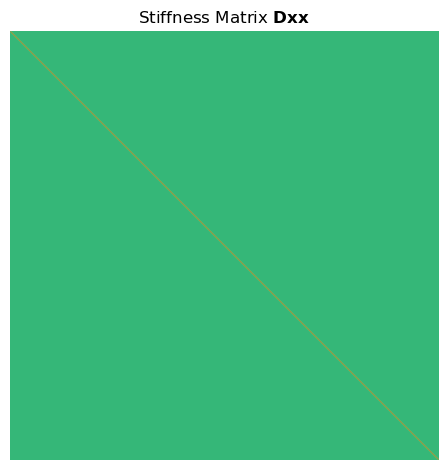

In [4]:

# ---------------------------------------------------------------
# Mass matrix M_ij (Eq 6.56)
# ---------------------------------------------------------------
Dxx = np.zeros((nx,nx), dtype=float)
for i in range(1, nx-1):
    for j in range (1, nx-1):
        if j==i:
            Dxx[i,j] = -2/dx**2
        elif j==i+1:
            Dxx[i,j] = 1/dx**2
        elif j==i-1:
            Dxx[i,j] = 1/dx**2
        else:
            Dxx[i,j] = 0
            
# Corner elements
#Dxx[0,0] = b*dx
#Dxx[0,1] = -1*b*dx
Dxx[1,0] = 1/dx**2
#A[nx-1,nx-1] = 1*b*dx
#A[nx-2,nx-1] = -1*b*dx
Dxx[nx-2,nx-1] = 1/dx**2

# ---------------------------------------------------------------
# Display inverse mass matrix inv(M)
# ---------------------------------------------------------------
plt.imshow(Dxx)
plt.title('Stiffness Matrix $\mathbf{Dxx}$')
plt.axis("off")
plt.tight_layout()
plt.show()

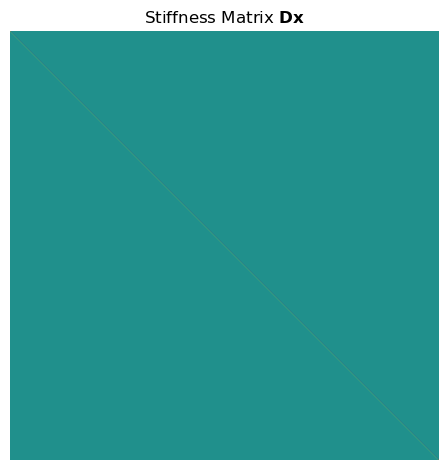

In [5]:

# ---------------------------------------------------------------
# Mass matrix M_ij (Eq 6.56)
# ---------------------------------------------------------------
Dx = np.zeros((nx,nx), dtype=float)
for i in range(1, nx-1):
    for j in range (1, nx-1):
        if j==i:
            Dx[i,j] = 0
        elif j==i+1:
            Dx[i,j] = -1/(2*dx) ####-
        elif j==i-1:
            Dx[i,j] = 1/(2*dx) ####
        else:
            Dx[i,j] = 0
            
# Corner elements
Dx[0,0] = -1/dx
Dx[0,1] = 1/dx
Dx[1,0] = 1/(2*dx)
Dx[nx-1,nx-1] = 1/dx
Dx[nx-2,nx-1] = -1/(2*dx)
Dx[nx-1,nx-2] = -1/dx

DxT = np.matrix.transpose(Dx)

# ---------------------------------------------------------------
# Display inverse mass matrix inv(M)
# ---------------------------------------------------------------
plt.imshow(Dx)
plt.title('Stiffness Matrix $\mathbf{Dx}$')
plt.axis("off")
plt.tight_layout()
plt.show()

In [6]:
I = np.zeros((nx,nx), dtype=float)
for i in range(0, nx-1):
    for j in range (0, nx-1):
        if j==i:
            I[i,j] = 1
        else:
            I[i,j] = 0
            
I[0,0] = 1
I[nx-1,nx-1] = 1

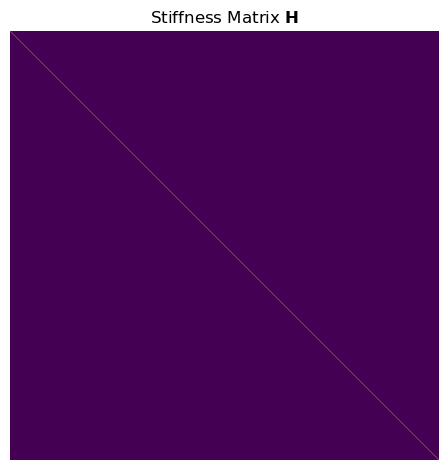

In [7]:
# ---------------------------------------------------------------
# Mass matrix M_ij (Eq 6.56)
# ---------------------------------------------------------------
H = np.zeros((nx,nx), dtype=float)
for i in range(0, nx-1):
    for j in range (0, nx-1):
        if j==i:
            H[i,j] = dx
        else:
            H[i,j] = 0
            
H[0,0] = dx/2
H[nx-1,nx-1] = dx/2
            
Hinv = np.linalg.inv(H)
    
plt.imshow(H)
plt.title('Stiffness Matrix $\mathbf{H}$')
plt.axis("off")
plt.tight_layout()
plt.show()

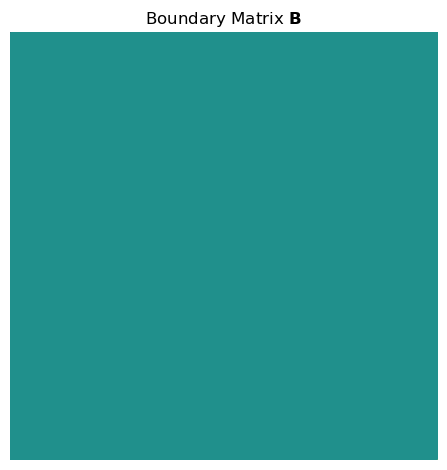

In [8]:
# ---------------------------------------------------------------
# Mass matrix M_ij (Eq 6.56)
# ---------------------------------------------------------------
B = np.zeros((nx,nx), dtype=float)
for i in range(1, nx-1):
    for j in range (1, nx-1):
        if j==i:
            B[i,j] = 0
        elif j==i+1:
            B[i,j] = 0
        elif j==i-1:
            B[i,j] = 0
        else:
            B[i,j] = 0
            
# Corner elements
B[0,0] = -1
B[nx-1,nx-1] = 1

BT = np.matrix.transpose(B)

# ---------------------------------------------------------------
# Display inverse mass matrix inv(M)
# ---------------------------------------------------------------
plt.imshow(B)
plt.title('Boundary Matrix $\mathbf{B}$')
plt.axis("off")
plt.tight_layout()
plt.show()

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# ---------------------------------------------------------------
# Initial conditions
# ---------------------------------------------------------------
# Reset u using your original initial-condition code
# before running this cell.

u = np.exp(
    -(np.asarray(x).reshape(-1) - xmax/4)**2
    + 1j*5*(np.asarray(x).reshape(-1) - xmax/4)
)

# ---------------------------------------------------------------
# Time integration matrices
# ---------------------------------------------------------------
A = 1j * (
    Dxx
    + tau1 * Hinv @ DxT @ B
    - tau0 * Hinv @ BT @ Hinv @ B
)

Am = I - (dt / 2) * A
Ap = I + (dt / 2) * A

# More efficient than calculating the inverse explicitly
M = np.linalg.solve(Am, Ap)

# ---------------------------------------------------------------
# Calculate and store animation frames
# ---------------------------------------------------------------
iplot = 10

times = [0.0]
numerical_frames = [np.abs(u)**2]
exact_frames = [
    np.abs(np.asarray(exactsol(x, 0, 5)).reshape(-1))**2
]

norm_initial = np.real(np.vdot(u, H @ u))
norm_history = [norm_initial]

nsteps = int(round(tend / dt))

for it in range(1, nsteps + 1):

    u = M @ u
    t = it * dt

    norm_current = np.real(np.vdot(u, H @ u))
    norm_history.append(norm_current)

    if it % iplot == 0 or it == nsteps:

        times.append(t)

        numerical_frames.append(np.abs(u)**2)

        U = np.asarray(exactsol(x, t, 5)).reshape(-1)
        exact_frames.append(np.abs(U)**2)

# ---------------------------------------------------------------
# Plot setup
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 4))

line1, = ax.plot(
    x, numerical_frames[0],
    'k', lw=1.5, label='FEM'
)

line2, = ax.plot(
    x, exact_frames[0],
    'r', lw=1.5, label='Exact'
)

ax.set_xlabel('x (m)')
ax.set_ylabel('Probability Density')
ax.legend()
ax.grid(True)

# Fix axis limits across all frames
all_values = np.concatenate(
    numerical_frames + exact_frames
)

ax.set_ylim(0, max(all_values) * 1.1)

# ---------------------------------------------------------------
# Animation function
# ---------------------------------------------------------------
def update(frame):

    line1.set_ydata(numerical_frames[frame])
    line2.set_ydata(exact_frames[frame])

    ax.set_title(
        f'Finite Elements 1D Animation | t = {times[frame]:.3f}'
    )

    return line1, line2

ani = FuncAnimation(
    fig,
    update,
    frames=len(times),
    interval=50,
    blit=False,
    repeat=False
)

plt.close(fig)

# ---------------------------------------------------------------
# Display animation with playback controls
# ---------------------------------------------------------------
display(HTML(ani.to_jshtml()))

# ---------------------------------------------------------------
# Stability diagnostics
# ---------------------------------------------------------------
print("Initial norm:", norm_initial)
print("Final norm:", norm_history[-1])
print(
    "Relative change:",
    (norm_history[-1] - norm_initial) / norm_initial
)

Initial norm: 1.2533141373155003
Final norm: 1.2533141373153012
Relative change: -1.5891786798509116e-13


In [10]:
ani.save("simulation.gif", writer="pillow", fps=20)